# Detección de Fallas en Maquinaria CNC (Mantenimiento Predictivo)
**Objetivo:** Entrenar un modelo de Machine Learning capaz de anticipar fallas industriales a partir de telemetría de sensores, aplicando técnicas de balanceo de clases y serialización para su posterior despliegue en producción.

In [1]:
# Librerías de sistema y rutas
from pathlib import Path
import joblib

# Manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine Learning: Preprocesamiento, Modelado y Evaluación
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Configuración de directorios mediante Pathlib para portabilidad absoluta
BASE_DIR = Path.cwd().parent
RAW_DIR = BASE_DIR / "data" / "raw"
MODELS_DIR = BASE_DIR / "models"
PATH_RAW_DATA = RAW_DIR / "ai4i2020.csv"

## 1. Adquisición y Limpieza de Datos
Se ingesta el dataset crudo, se aísla la variable objetivo (Target) y se eliminan las características (Features) que no aportan valor predictivo o que generan fuga de datos algorítmica (Data Leakage).

In [2]:
# Ingesta de la base de datos
df = pd.read_csv(PATH_RAW_DATA)

# Aislamiento de la variable a predecir
y = df["Machine failure"]

# Prevención de Data Leakage y eliminación de ruido
# Se descartan identificadores únicos y variables derivadas directas de fallas (TWF, HDF, PWF, OSF, RNF)
cols_to_drop = [
    "UDI", "Product ID", "Type", "Machine failure", 
    "TWF", "HDF", "PWF", "OSF", "RNF"
]
X = df.drop(columns=cols_to_drop)

## 2. Particionamiento del Dataset (Train/Test Split)
Se evalúa la asimetría poblacional de las clases. Se implementa un particionamiento estratificado (`stratify=y`) para garantizar que la distribución matemática original se mantenga intacta entre los conjuntos de entrenamiento y validación.

In [3]:
# Auditoría de desbalanceo de clases
print("Distribución original de la variable objetivo:")
print(y.value_counts(normalize=True) * 100)

# División estratificada de los datos (80% entrenamiento, 20% validación)
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42,
    stratify=y
)

# Verificación de integridad dimensional
print(f"\nDimensiones de entrenamiento (X_train): {X_train.shape}")
print(f"Dimensiones de validación (X_test): {X_test.shape}")

Distribución original de la variable objetivo:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Dimensiones de entrenamiento (X_train): (8000, 5)
Dimensiones de validación (X_test): (2000, 5)


## 3. Preprocesamiento Matemático y Entrenamiento
Se estandariza la varianza de las magnitudes continuas. Posteriormente, se entrena un algoritmo de Bosque Aleatorio aplicando un factor de penalización ponderado (`class_weight='balanced'`) para corregir el desbalanceo durante el ajuste de pesos.

In [4]:
# Instanciación del escalador
scaler = StandardScaler()

# Ajuste y transformación exclusiva sobre el set de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Transformación del set de validación aplicando los parámetros previamente aprendidos
X_test_scaled = scaler.transform(X_test)

# Instanciación y entrenamiento del modelo algorítmico
modelo_rf = RandomForestClassifier(
    class_weight='balanced', 
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train_scaled, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

## 4. Inferencia y Evaluación Técnica
El modelo se somete a evaluación contra el conjunto oculto (`X_test_scaled`). Para problemas industriales asimétricos, se prioriza la optimización y lectura de las métricas de Recall (Sensibilidad) y Precisión sobre el Accuracy global.

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.70      0.69      0.70        68

    accuracy                           0.98      2000
   macro avg       0.85      0.84      0.84      2000
weighted avg       0.98      0.98      0.98      2000



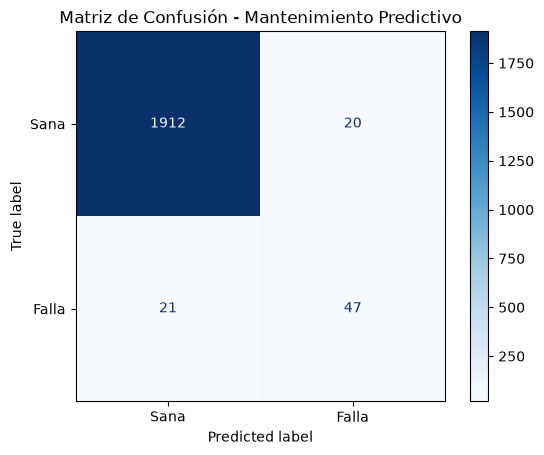

In [5]:
# Inferencia algorítmica
y_pred = modelo_rf.predict(X_test_scaled)

# Extracción de métricas de rendimiento
matriz_conf = confusion_matrix(y_test, y_pred)
reporte_clas = classification_report(y_test, y_pred)

print("Reporte de Clasificación:")
print(reporte_clas)

# Renderizado visual formal de la Matriz de Confusión
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_conf, display_labels=["Sana", "Falla"])
disp.plot(cmap='Blues', values_format='d')
plt.title("Matriz de Confusión - Mantenimiento Predictivo")
plt.show()

## 5. Persistencia de Artefactos Matemáticos (Serialización)
Exportación de los objetos (escalador estadístico y modelo entrenado) al disco duro mediante `joblib`. Estos artefactos serán consumidos por el pipeline de producción en el despliegue local.

In [6]:
# Creación del directorio de destino si no existe en la arquitectura del proyecto
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Serialización en disco del escalador
scaler_path = MODELS_DIR / 'scaler.joblib'
joblib.dump(scaler, scaler_path)
print(f"Scaler exportado correctamente en: {scaler_path}")

# Serialización en disco del modelo Random Forest
model_path = MODELS_DIR / 'rf_model.joblib'
joblib.dump(modelo_rf, model_path)
print(f"Modelo Random Forest exportado correctamente en: {model_path}")

Scaler exportado correctamente en: e:\dev\data\predictive_maintenance_ml\models\scaler.joblib
Modelo Random Forest exportado correctamente en: e:\dev\data\predictive_maintenance_ml\models\rf_model.joblib
